In [1]:
# Code from https://docs.scvi-tools.org/en/1.1.0/tutorials/notebooks/scrna/scarches_scvi_tools.html 
# and https://docs.scvi-tools.org/en/1.0.0/tutorials/notebooks/tabula_muris.html

import os
import time
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=DeprecationWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [2]:
import tempfile

import anndata
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import seaborn as sns
import torch
import rapids_singlecell as rsc

/beegfs/home/kli/.local/share/mamba/envs/scANVI/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import rmm
import cupy as cp
from rmm.allocators.cupy import rmm_cupy_allocator

rmm.reinitialize(
    managed_memory=True,  # Allows oversubscription
    pool_allocator=False,  # default is False
    devices=0,  # GPU device IDs to register. By default registers only GPU 0.
)
cp.cuda.set_allocator(rmm_cupy_allocator)

In [4]:
os.chdir("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/seurat")

### Read in the reference single cell RNA-seq data

In [5]:
adata = sc.read_mtx("scrna_phase_clustering_counts.mtx").T

genes = pd.read_csv("scrna_phase_clustering_genes.tsv", header=None)[0]
cells = pd.read_csv("scrna_phase_clustering_cells.tsv", header=None)[0]

adata.var_names = genes
adata.obs_names = cells

meta = pd.read_csv("scrna_phase_clustering_metadata.tsv", sep="\t", index_col=0)
adata.obs = meta.loc[adata.obs_names]

In [6]:
ref = adata.copy()

In [7]:
del adata

### Read in the Visium data

In [8]:
print(f"[{time.strftime('%Y-%m-%d %H:%M:%S', time.localtime())}] Start reading Visium HD data")
visium = sc.read_h5ad("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/adata_with_spatial_7samples_with_pos_cluster2.0.h5ad")

[2026-03-20 15:43:29] Start reading Visium HD data


In [9]:
query = visium.copy()

In [10]:
del visium

In [11]:
common_genes = ref.var_names.intersection(query.var_names)

In [12]:
len(common_genes)

12784

In [13]:
query = query[:, common_genes].copy()
ref = ref[:, common_genes].copy()

### Run highly variable gene selection on the reference data

In [14]:
ref.layers["counts"] = ref.X.copy()

In [15]:
sc.pp.highly_variable_genes(ref, n_top_genes=3000, batch_key="name", subset=True, flavor='seurat_v3')

In [16]:
query = query[:, ref.var_names].copy()

In [17]:
len(query.var_names)

3000

### Train reference

In [18]:
scvi.model.SCVI.setup_anndata(ref, batch_key="name", layer="counts")

In [19]:
scvi_ref = scvi.model.SCVI(
    ref,
    use_layer_norm="both",
    use_batch_norm="none",
    encode_covariates=True,
    dropout_rate=0.2,
    n_layers=2,
)
scvi_ref.train(batch_size=10240, max_epochs=100)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 100/100: 100%|██████████| 100/100 [01:36<00:00,  1.04it/s, v_num=1, train_loss=1.05e+3]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [01:36<00:00,  1.04it/s, v_num=1, train_loss=1.05e+3]


In [20]:
SCVI_LATENT_KEY = "X_scVI"

ref.obsm[SCVI_LATENT_KEY] = scvi_ref.get_latent_representation()
sc.pp.neighbors(ref, use_rep=SCVI_LATENT_KEY)
sc.tl.leiden(ref)
sc.tl.umap(ref)

... storing 'orig.ident' as categorical
... storing 'name' as categorical
... storing 'stage' as categorical
... storing 'decontX_clusters' as categorical
... storing 'Doublet_classifications' as categorical
... storing 'Phase' as categorical
... storing 'old.ident' as categorical
... storing 'MCA_annotate' as categorical
... storing 'external_annotation' as categorical
... storing 'HCL_annotate' as categorical
... storing 'res1.5.annotation' as categorical
... storing 'res0.4.annotation' as categorical


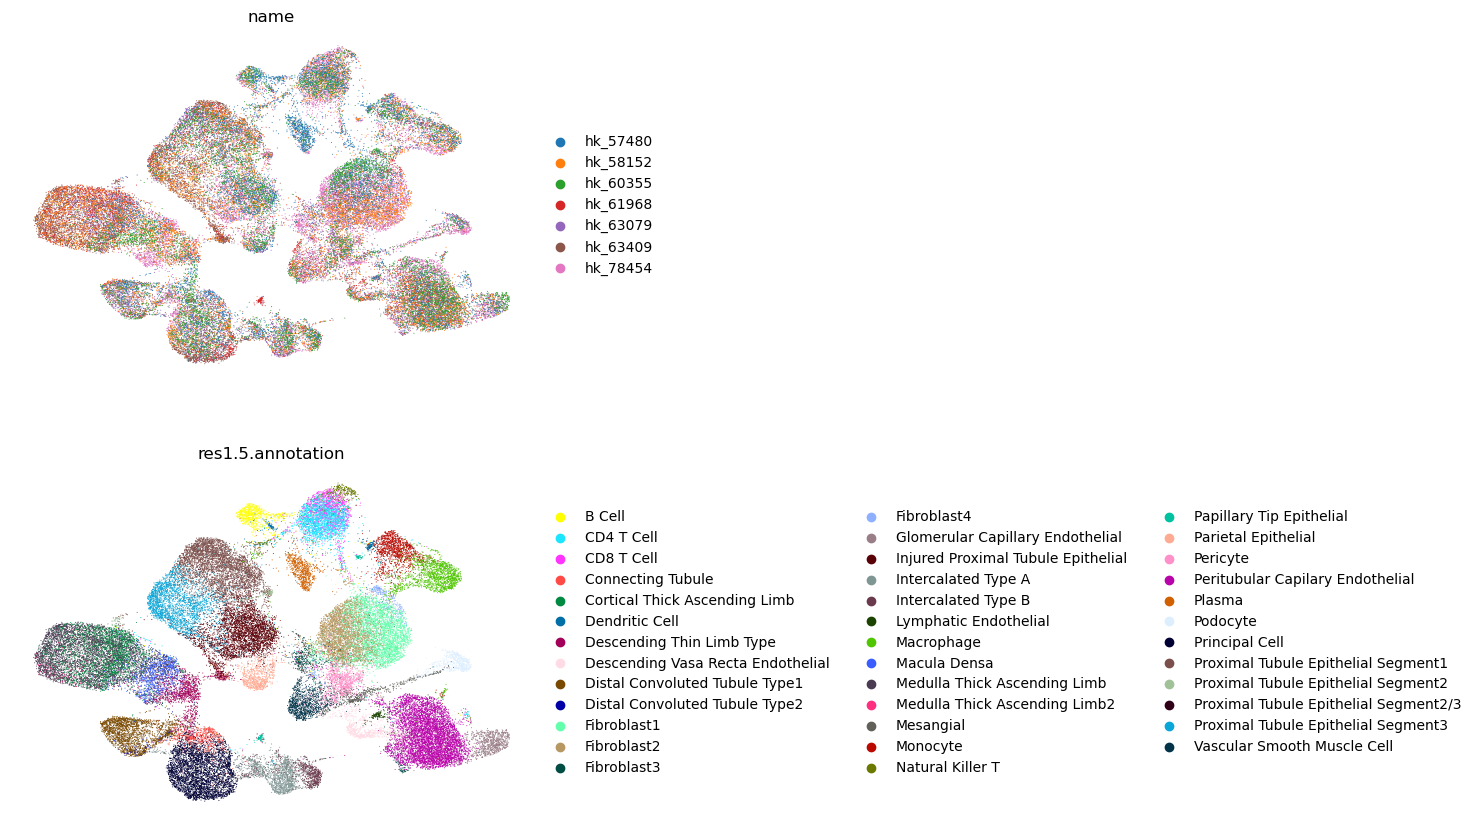

In [21]:
sc.pl.umap(
    ref,
    color=["name", "res1.5.annotation"],
    frameon=False,
    ncols=1,
)

### Update with query

In [22]:
scvi_ref.save("scvi_ref_1", overwrite=True)

In [23]:
query.obs["name"] = query.obs["sample"]

In [24]:
query.obs["res1.5.annotation"] = query.obs["leiden_harmony_2.0"]

In [25]:
scvi.model.SCVI.prepare_query_anndata(query, scvi_ref)

INFO     Found 100.0% reference vars in query data.                                                                


#### Now we create the new query model instance

In [26]:
query.layers["counts"] = query.layers["filtered_counts"]

In [27]:
scvi_query = scvi.model.SCVI.load_query_data(
    query,
    scvi_ref,
)

In [28]:
scvi_query.train(max_epochs=200, plan_kwargs={"weight_decay": 0.0}, batch_size=5120)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 200/200: 100%|██████████| 200/200 [12:09<00:00,  3.66s/it, v_num=1, train_loss=153]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [12:09<00:00,  3.65s/it, v_num=1, train_loss=153]


In [29]:
query.obsm[SCVI_LATENT_KEY] = scvi_query.get_latent_representation()

In [39]:
# skip the following, since it runs super slow
#sc.pp.neighbors(query, use_rep=SCVI_LATENT_KEY)
#sc.tl.leiden(query)
#sc.tl.umap(query)

## Reference mapping with SCANVI

### Train reference

In [30]:
SCANVI_LABELS_KEY = "labels_scanvi"

ref.obs[SCANVI_LABELS_KEY] = ref.obs["res1.5.annotation"].values

In [31]:
scanvi_ref = scvi.model.SCANVI.from_scvi_model(
    scvi_ref,
    unlabeled_category="Unknown",
    labels_key=SCANVI_LABELS_KEY,
)

In [32]:
scanvi_ref.train(max_epochs=100, n_samples_per_label=100, batch_size=10240)

INFO     Training for 100 epochs.                                                                                  


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 100/100: 100%|██████████| 100/100 [02:06<00:00,  1.26s/it, v_num=1, train_loss=1.04e+3]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [02:06<00:00,  1.27s/it, v_num=1, train_loss=1.04e+3]


In [33]:
SCANVI_LATENT_KEY = "X_scANVI"

ref.obsm[SCANVI_LATENT_KEY] = scanvi_ref.get_latent_representation()
sc.pp.neighbors(ref, use_rep=SCANVI_LATENT_KEY)
sc.tl.leiden(ref)
sc.tl.umap(ref)

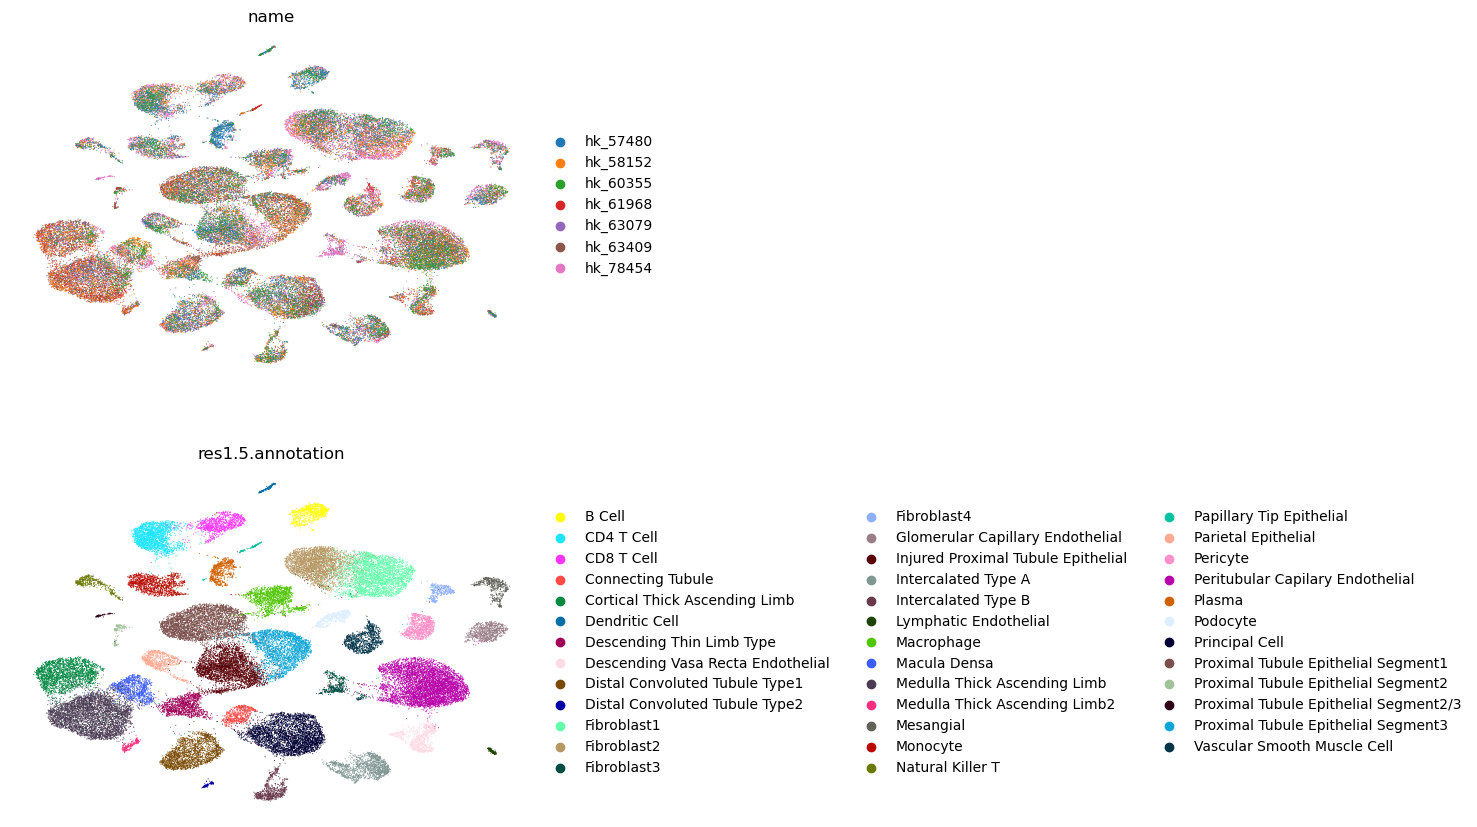

In [34]:
sc.pl.umap(
    ref,
    color=["name", "res1.5.annotation"],
    frameon=False,
    ncols=1,
)

### Update with query

In [35]:
scvi.model.SCANVI.prepare_query_anndata(query, scanvi_ref)

INFO     Found 100.0% reference vars in query data.                                                                


In [36]:
scanvi_query = scvi.model.SCANVI.load_query_data(query, scanvi_ref)

In [37]:
scanvi_query.train(
    max_epochs=100,
    plan_kwargs={"weight_decay": 0.0},
    check_val_every_n_epoch=10,
    batch_size=10240
)

INFO     Training for 100 epochs.                                                                                  


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 100/100: 100%|██████████| 100/100 [13:47<00:00,  8.63s/it, v_num=1, train_loss=147]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [13:47<00:00,  8.27s/it, v_num=1, train_loss=147]


In [39]:
SCANVI_PREDICTIONS_KEY = "predictions_scanvi"

query.obsm[SCANVI_LATENT_KEY] = scanvi_query.get_latent_representation()
query.obs[SCANVI_PREDICTIONS_KEY] = scanvi_query.predict()

In [40]:
query.obs

,sample,cell_id,region,x_pixel,y_pixel,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,n_counts,leiden_harmony_2.0,name,res1.5.annotation,_scvi_batch,_scvi_labels,labels_scanvi,predictions_scanvi
63511_cellid_000000001-1,63511,63511_cellid_000000001-1,63511_cell_boundaries,2288.075437,3484.848166,117,4.770685,134.0,4.905275,0.0,0.000000,0.000000,133.0,1,63511,1,9,38,Unknown,Pericyte
63511_cellid_000000002-1,63511,63511_cellid_000000002-1,63511_cell_boundaries,2076.487178,1813.933035,879,6.779922,1315.0,7.182352,3.0,1.386294,0.228137,1309.0,25,63511,25,9,38,Unknown,Podocyte
63511_cellid_000000003-1,63511,63511_cellid_000000003-1,63511_cell_boundaries,2466.581858,2585.659459,148,5.003946,176.0,5.176150,2.0,1.098612,1.136364,176.0,18,63511,18,9,38,Unknown,Distal Convoluted Tubule Type1
63511_cellid_000000005-1,63511,63511_cellid_000000005-1,63511_cell_boundaries,2350.877270,1856.848746,23,3.178054,25.0,3.258096,3.0,1.386294,12.000000,25.0,2,63511,2,9,38,Unknown,Proximal Tubule Epithelial Segment3
63511_cellid_000000006-1,63511,63511_cellid_000000006-1,63511_cell_boundaries,3760.766724,2499.680373,109,4.700480,123.0,4.820282,1.0,0.693147,0.813008,123.0,1,63511,1,9,38,Unknown,Fibroblast2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76997_cellid_000352505-1,76997,76997_cellid_000352505-1,76997_cell_boundaries,47999.821970,50186.691008,61,4.127134,65.0,4.189655,1.0,0.693147,1.538462,64.0,19,76997,19,13,38,Unknown,Fibroblast2
76997_cellid_000352615-1,76997,76997_cellid_000352615-1,76997_cell_boundaries,46734.990638,50176.710581,24,3.218876,24.0,3.218876,1.0,0.693147,4.166667,24.0,5,76997,5,13,38,Unknown,Fibroblast2
76997_cellid_000353017-1,76997,76997_cellid_000353017-1,76997_cell_boundaries,49039.145638,49886.874420,24,3.218876,26.0,3.295837,0.0,0.000000,0.000000,25.0,22,76997,22,13,38,Unknown,Fibroblast2
76997_cellid_000353569-1,76997,76997_cellid_000353569-1,76997_cell_boundaries,49024.063610,49989.827713,22,3.135494,26.0,3.295837,3.0,1.386294,11.538462,26.0,22,76997,22,13,38,Unknown,Fibroblast2


Text(0, 0.5, 'Observed')

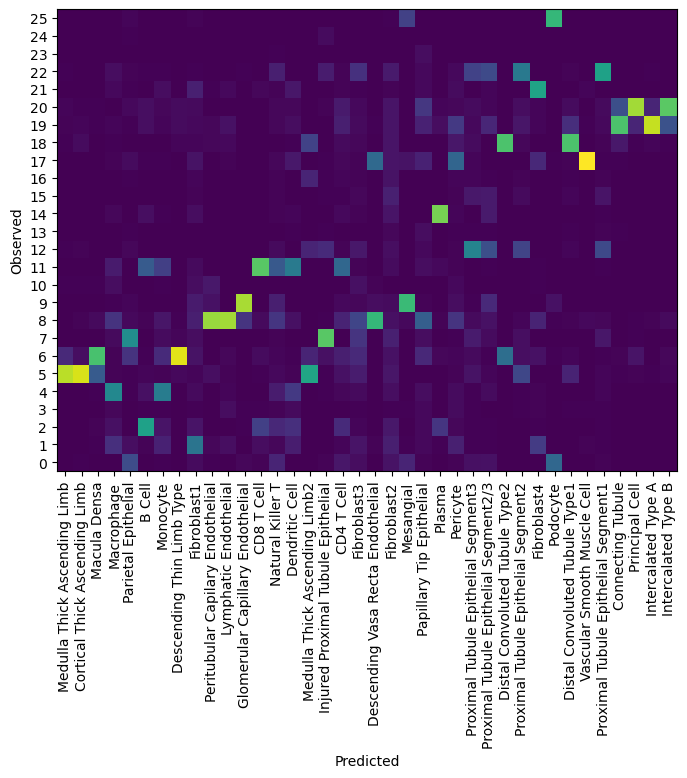

In [41]:
df = (
    query.obs.groupby(["leiden_harmony_2.0", SCANVI_PREDICTIONS_KEY])
    .size()
    .unstack(fill_value=0)
)
norm_df = df / df.sum(axis=0)

y_vals = np.arange(len(norm_df.index))

col_score = (norm_df.T * y_vals).sum(axis=1)

col_order = col_score.sort_values().index

norm_df_sorted = norm_df[col_order]


plt.figure(figsize=(8, 6))
plt.pcolor(norm_df_sorted)
plt.xticks(np.arange(0.5, len(col_order), 1), col_order, rotation=90)
plt.yticks(np.arange(0.5, len(norm_df.index), 1), norm_df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

... storing 'labels_scanvi' as categorical
... storing 'predictions_scanvi' as categorical


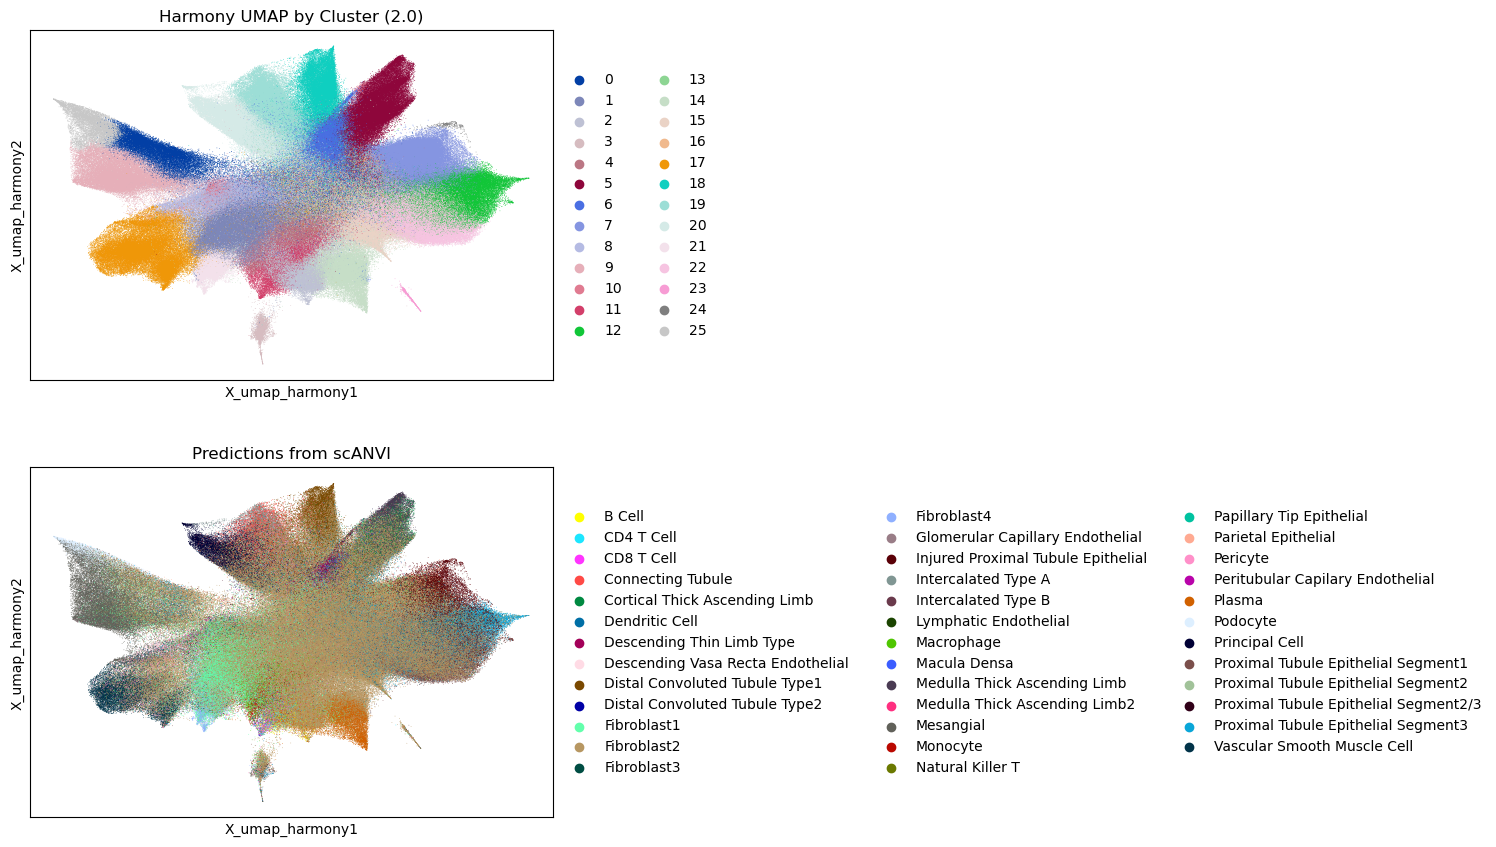

In [42]:
sc.pl.embedding(query, basis="X_umap_harmony", color=["leiden_harmony_2.0", "predictions_scanvi"], legend_loc="right margin", title=["Harmony UMAP by Cluster (2.0)", "Predictions from scANVI"], size=1.0, ncols=1)